Computational Physics Sheet 4

In [21]:
import numpy as np
import matplotlib.pyplot as plt


Exercise 1: irst couple hundred trajectories of the MC history of {m}

Acceptance rate (N_md=100): 99.99%
Acceptance rate (N_md=4):   64.73%


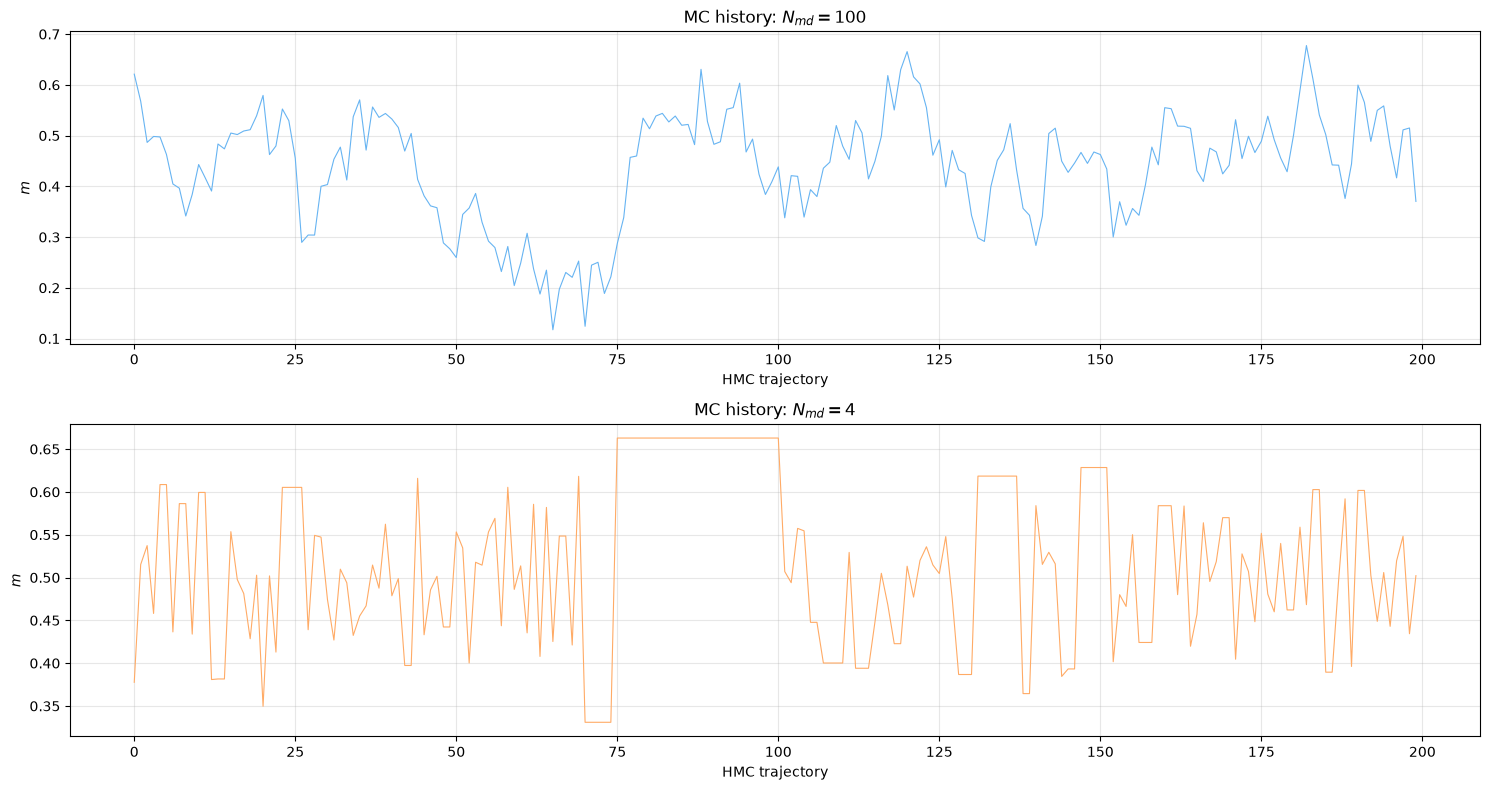

In [22]:


# Simulation parameters

nsites = 5
beta = 1.0
beta_J = 0.1
beta_h = 0.5

J = beta_J / beta
J_hat = J / nsites
h = beta_h / beta

tau = 1.0

n_therm = 1000
n_meas = 12800

# Plot colors
colors = ["#67B4F2", "#FFAB66"]


# HMC Hamiltonian and force


def hmc_hamiltonian(p, phi, N, beta, J_hat, h):
    """Calculate the artificial HMC Hamiltonian"""

    kinetic = 0.5 * p**2

    x = beta * h + phi
    potential = (
        0.5 * phi**2 / (beta * J_hat)
        - N * np.logaddexp(x, -x)
    )

    return kinetic + potential


def force(phi, N, beta, J_hat, h):
    """Calculate dp/dt from the Hamiltonian"""

    return (
        -phi / (beta * J_hat)
        + N * np.tanh(beta * h + phi)
    )


# Leapfrog algorithm


def leapfrog(p0, phi0, N_md, N, beta, J_hat, h, tau=1.0):
    """Integrate Hamilton equations over a trajectory of length tau"""

    if N_md < 1:
        raise ValueError("N_md must be >= 1")

    epsilon = tau / N_md

    Pi = float(p0)
    Phi = float(phi0)

    # First half position step
    Phi += 0.5 * epsilon * Pi

    # N_md - 1 full steps
    for _ in range(N_md - 1):
        Pi += epsilon * force(Phi, N, beta, J_hat, h)
        Phi += epsilon * Pi

    # Final momentum step
    Pi += epsilon * force(Phi, N, beta, J_hat, h)

    # Final half position step
    Phi += 0.5 * epsilon * Pi

    return Pi, Phi


# HMC algorithm


def hmc_step(phi, N_md, N, beta, J_hat, h, rng, tau=1.0):
    """Perform one HMC update of the field phi"""

    # Sample fresh momentum
    p0 = rng.normal(0, 1)

    # Calculate initial Hamiltonian
    H0 = hmc_hamiltonian(p0, phi, N, beta, J_hat, h)

    # Propose new state using leapfrog integration
    pf, phif = leapfrog(
        p0, phi, N_md, N, beta, J_hat, h, tau=tau
    )

    # Calculate final Hamiltonian
    Hf = hmc_hamiltonian(pf, phif, N, beta, J_hat, h)

    # Hamiltonian difference
    dH = Hf - H0

    # Metropolis accept/reject step
    if np.isfinite(dH):
        if dH <= 0 or rng.random() < np.exp(-dH):
            return phif, True

    return phi, False


def run_hmc(phi0, N_md, N, beta, J_hat, h,
            n_therm, n_meas, rng, tau=1.0):
    """Run a HMC simulation and return field samples and acceptance rate"""

    phi = float(phi0)

    # Thermalization
    for _ in range(n_therm):
        phi, accepted = hmc_step(
            phi, N_md, N, beta, J_hat, h, rng, tau
        )

    # Measurement phase
    phi_samples = np.empty(n_meas)
    n_accepted = 0

    for i in range(n_meas):
        phi, accepted = hmc_step(
            phi, N_md, N, beta, J_hat, h, rng, tau
        )

        # Store the sample and count acceptance
        phi_samples[i] = phi
        n_accepted += int(accepted)

    acceptance_rate = n_accepted / n_meas

    return phi_samples, acceptance_rate


# Magnetization observable


def magnetization_observable(phi_samples, beta, h):
    """Calculate magnetization per site for each sampled phi"""

    return np.tanh(beta * h + phi_samples)



# Generate two Markov Chains


rng_100 = np.random.default_rng(seed=42)
rng_4 = np.random.default_rng(seed=123)

# MC 1: N_md = 100
phi_samples_100, acceptance_100 = run_hmc(
    phi0=0.0,
    N_md=100,
    N=nsites,
    beta=beta,
    J_hat=J_hat,
    h=h,
    n_therm=n_therm,
    n_meas=n_meas,
    rng=rng_100,
    tau=tau
)

# MC 2: N_md = 4
phi_samples_4, acceptance_4 = run_hmc(
    phi0=0.0,
    N_md=4,
    N=nsites,
    beta=beta,
    J_hat=J_hat,
    h=h,
    n_therm=n_therm,
    n_meas=n_meas,
    rng=rng_4,
    tau=tau
)


# Calculate magnetization for each configuration


m_samples_100 = magnetization_observable(
    phi_samples_100, beta, h
)

m_samples_4 = magnetization_observable(
    phi_samples_4, beta, h
)


# Print simulation results


print(f"Acceptance rate (N_md=100): {acceptance_100:.2%}")
print(f"Acceptance rate (N_md=4):   {acceptance_4:.2%}")


# Plot first 200 trajectories of the MC history


fig, axes = plt.subplots(2, 1, figsize=(15, 8))

# MC 1: N_md = 100
axes[0].plot(
    m_samples_100[:200],
    color=colors[0],
    linewidth=0.8
)

axes[0].set_title(r"MC history: $N_{md}=100$")
axes[0].set_xlabel("HMC trajectory")
axes[0].set_ylabel(r"$m$")
axes[0].grid(alpha=0.3)


# MC 2: N_md = 4
axes[1].plot(
    m_samples_4[:200],
    color=colors[1],
    linewidth=0.8
)

axes[1].set_title(r"MC history: $N_{md}=4$")
axes[1].set_xlabel("HMC trajectory")
axes[1].set_ylabel(r"$m$")
axes[1].grid(alpha=0.3)

plt.tight_layout()
# plt.savefig("figs/MC_history_comparison.pdf", dpi=300)
plt.show()

Autocorreltaion

Mean magnetization (N_md=100): 0.49531
Mean magnetization (N_md=4):   0.48651


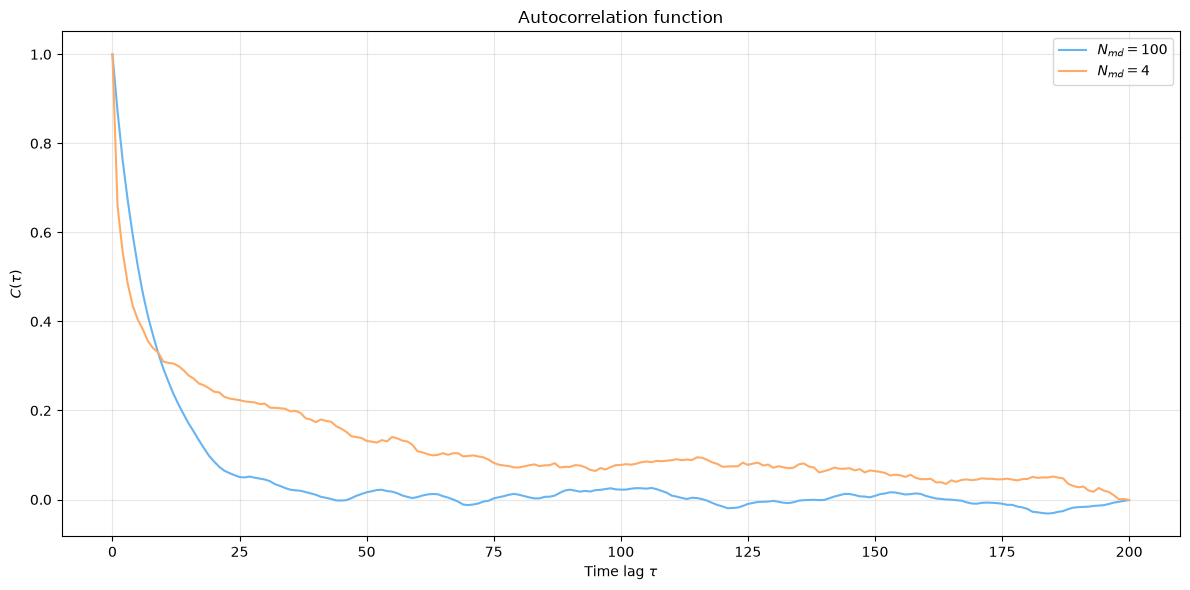

In [23]:
#Mean Magnetization for both Chains 
mean_m_100 = np.mean(m_samples_100)
mean_m_4 = np.mean(m_samples_4)

print(f"Mean magnetization (N_md=100): {mean_m_100:.5f}")
print(f"Mean magnetization (N_md=4):   {mean_m_4:.5f}")

# Calculate autocorrelation function

def autocorrelation(m_samples):
    """Calculate the normalized autocorrelation function"""

    N_samples = len(m_samples)
    mean_m = np.mean(m_samples)

    # Calculate deviations from the mean
    deviations = m_samples - mean_m

    # Calculate autocorrelation for each time lag
    gamma = np.empty(N_samples)

    for tau in range(N_samples):
        products = (
            deviations[:N_samples-tau]
            * deviations[tau:]
        )

        gamma[tau] = np.mean(products)

    # Normalize autocorrelation function
    C = gamma / gamma[0]

    return C


# Calculate autocorrelation for both MC chains


C_100 = autocorrelation(m_samples_100)
C_4 = autocorrelation(m_samples_4)


# Plot autocorrelation functions


max_tau = 200

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    np.arange(max_tau + 1),
    C_100[:max_tau + 1],
    color=colors[0],
    label=r"$N_{md}=100$"
)

ax.plot(
    np.arange(max_tau + 1),
    C_4[:max_tau + 1],
    color=colors[1],
    label=r"$N_{md}=4$"
)

ax.set_xlabel(r"Time lag $\tau$")
ax.set_ylabel(r"$C(\tau)$")
ax.set_title("Autocorrelation function")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
# plt.savefig("figs/autocorrelation.pdf", dpi=300)
plt.show()


Exercise 3: Binning

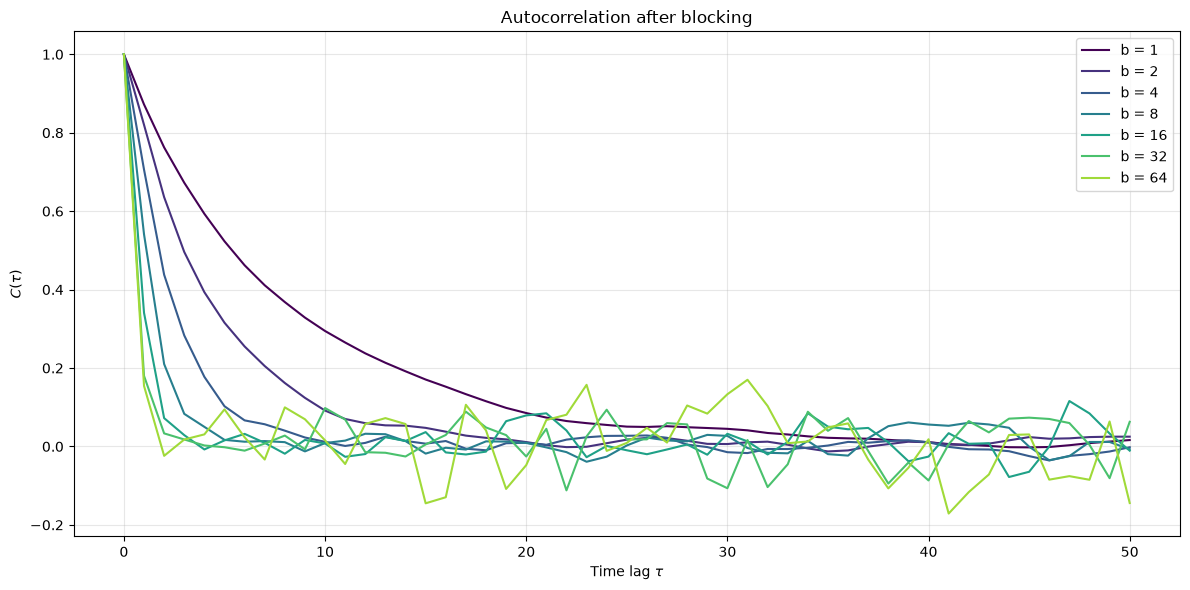

Naive standard errors:
Block size b =  1: Standard error = 0.000994
Block size b =  2: Standard error = 0.001360
Block size b =  4: Standard error = 0.001838
Block size b =  8: Standard error = 0.002415
Block size b = 16: Standard error = 0.002986
Block size b = 32: Standard error = 0.003468
Block size b = 64: Standard error = 0.003666


In [24]:
# Block sizes
block_sizes = [1, 2, 4, 8, 16, 32, 64]


# Function for blocking the data


def blocking(m_samples, b):
    """Calculate block averages for a given block size"""

    N_samples = len(m_samples)

    # Discard remaining values if N is not divisible by b
    N_blocks = N_samples // b
    trimmed_samples = m_samples[:N_blocks * b]

    # Reshape data into blocks and calculate block averages
    blocked_samples = trimmed_samples.reshape(N_blocks, b).mean(axis=1)

    return blocked_samples


# Calculate blocked data, autocorrelation and standard error

blocked_data = {}
blocked_autocorrelation = {}
standard_errors = {}

for b in block_sizes:

    # Generate blocked data
    blocked_samples = blocking(m_samples_100, b)
    blocked_data[b] = blocked_samples

    # Calculate autocorrelation
    C = autocorrelation(blocked_samples)
    blocked_autocorrelation[b] = C

    # Calculate naive standard error
    sigma = np.std(blocked_samples, ddof=1)
    N_blocks = len(blocked_samples)

    standard_errors[b] = sigma / np.sqrt(N_blocks)

# Plot autocorrelation functions for different block sizes

max_tau = 50

fig, ax = plt.subplots(figsize=(12, 6))

for i, b in enumerate(block_sizes):

    C = blocked_autocorrelation[b]

    ax.plot(
        np.arange(max_tau + 1),
        C[:max_tau + 1],
        color=plt.cm.viridis(i / len(block_sizes)),
        label=f"b = {b}"
    )

ax.set_xlabel(r"Time lag $\tau$")
ax.set_ylabel(r"$C(\tau)$")
ax.set_title("Autocorrelation after blocking")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


# Print naive standard errors


print("Naive standard errors:")

for b in block_sizes:
    print(
        f"Block size b = {b:2d}: "
        f"Standard error = {standard_errors[b]:.6f}"
    )


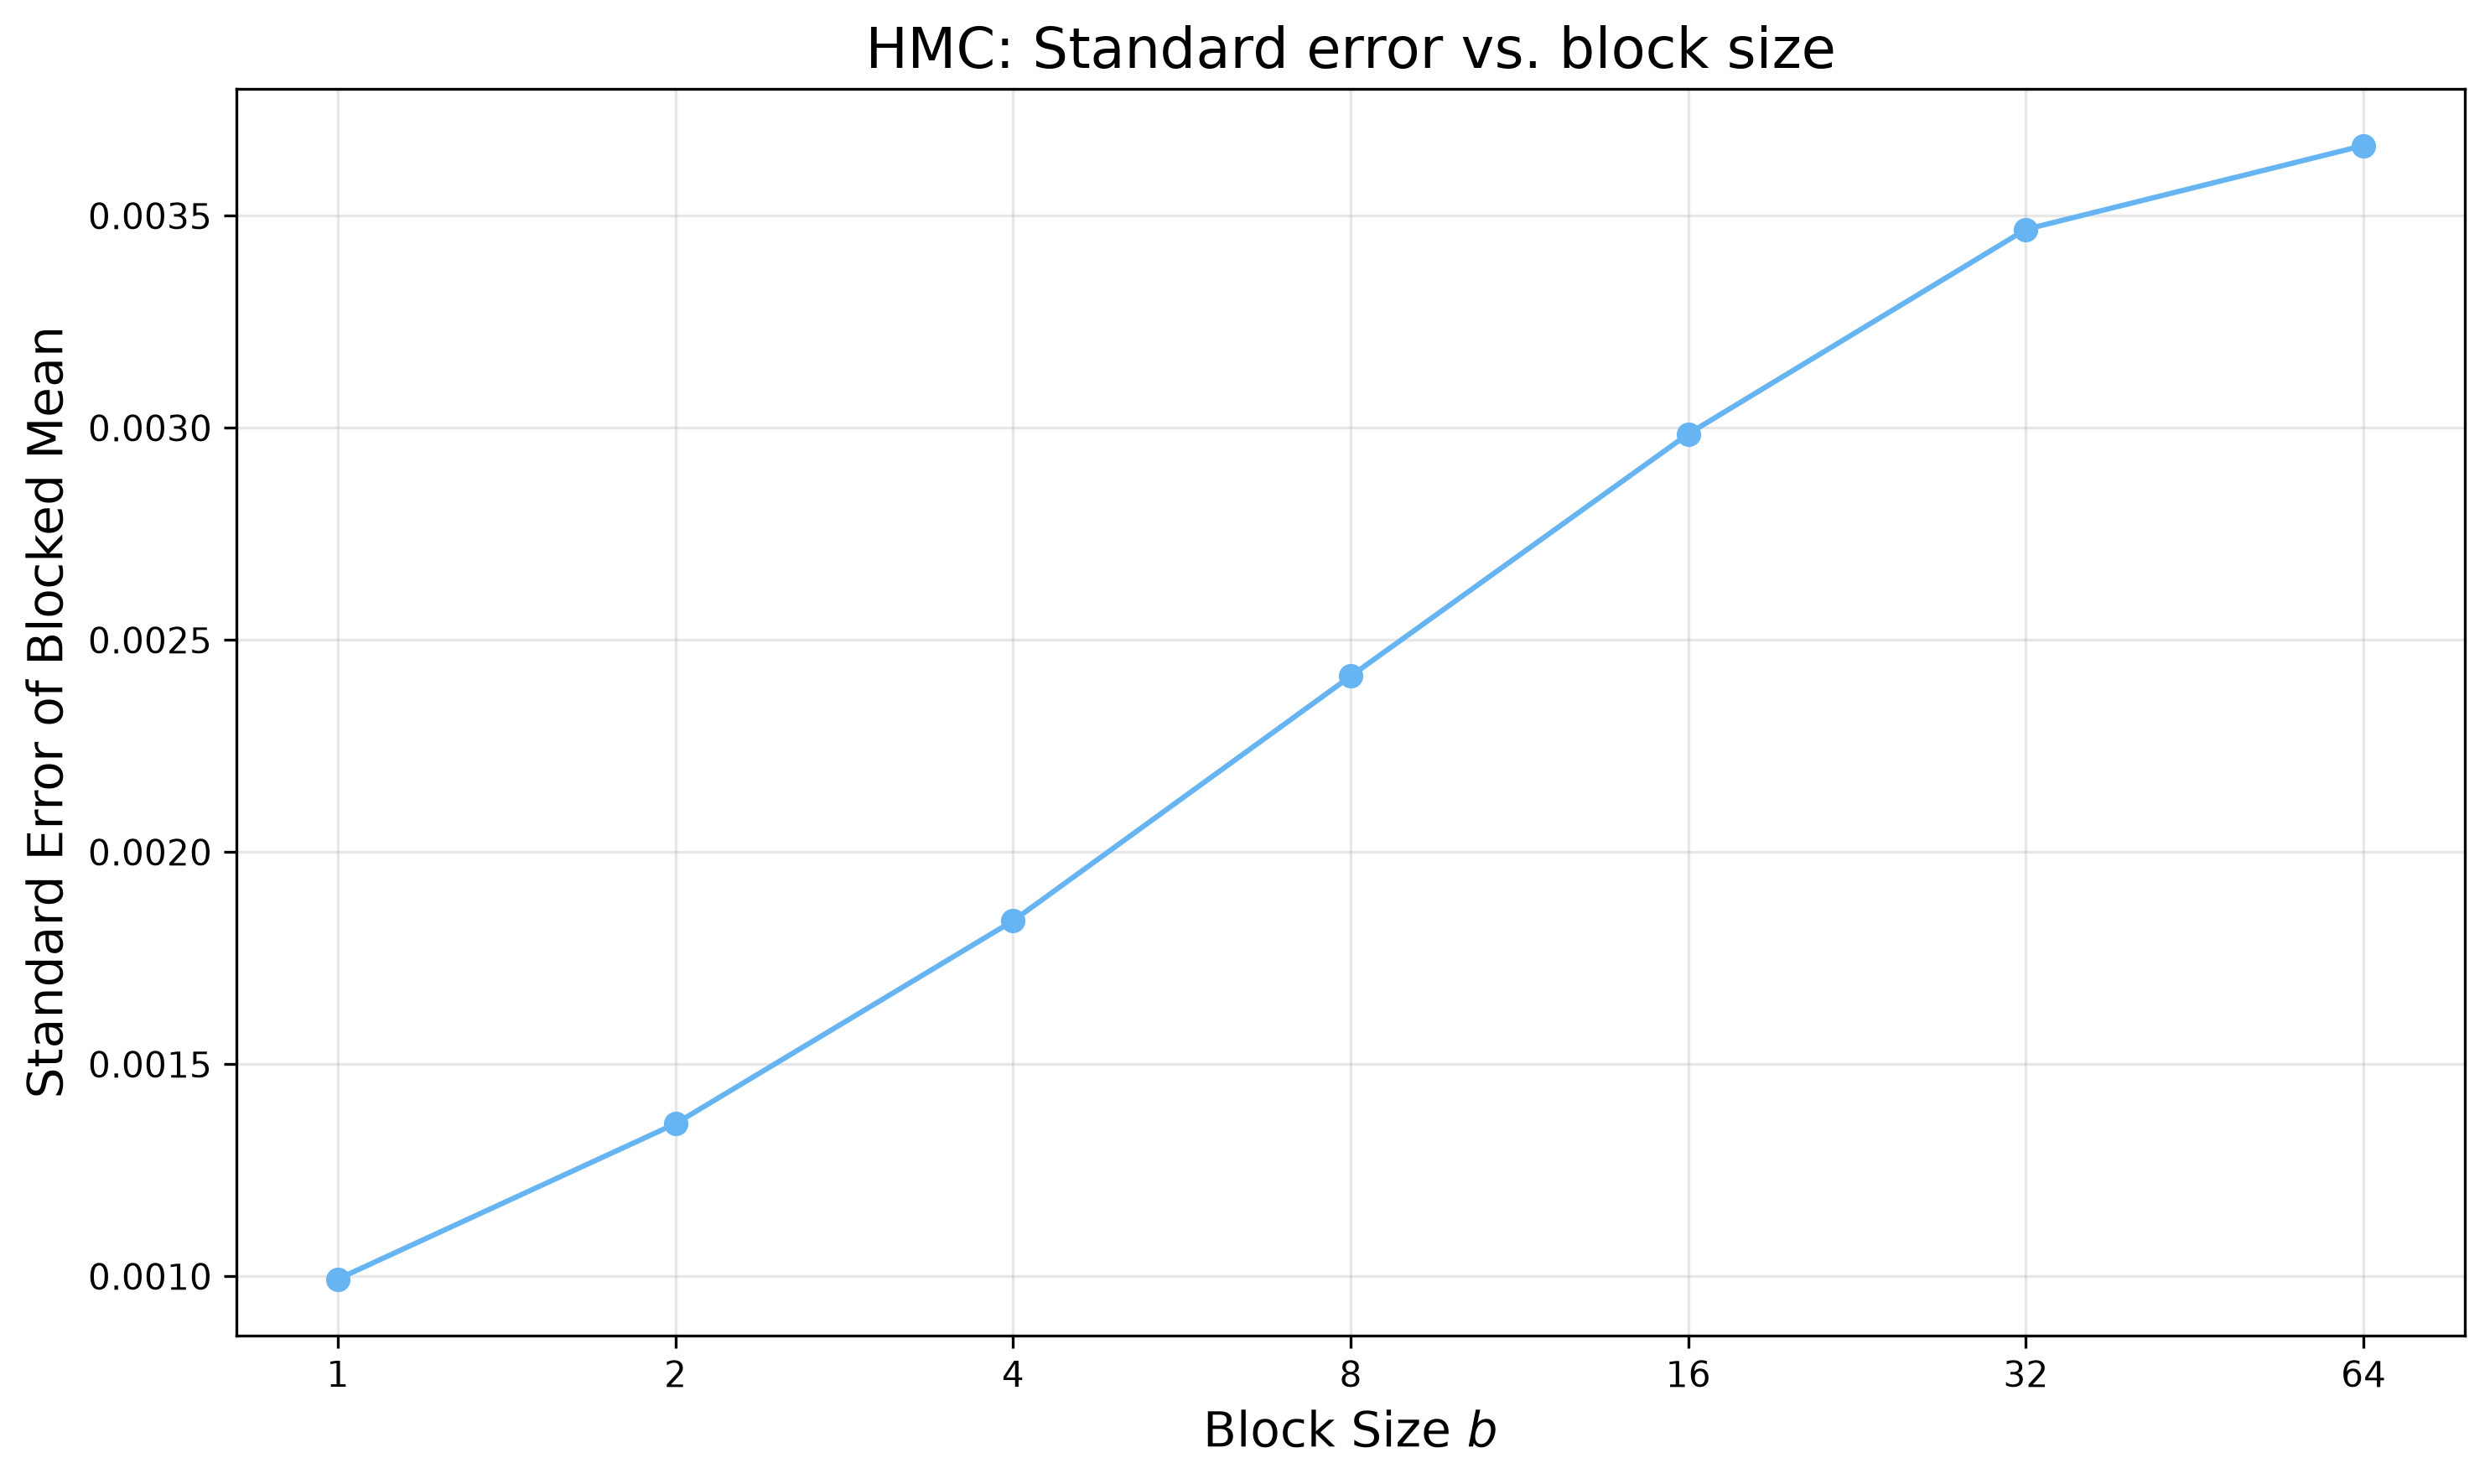

In [25]:
# make list of standard errors for plotting
standard_errors_list = [standard_errors[b] for b in block_sizes]
fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.plot(
    block_sizes,
    standard_errors_list,
    marker="o",
    linewidth=1.5,
    color=colors[0]
)
ax.set_xscale("log", base=2)
ax.set_xticks(block_sizes)
ax.set_xticklabels(block_sizes)

ax.set_xlabel(r"Block Size $b$", fontsize=14)
ax.set_ylabel(r"Standard Error of Blocked Mean", fontsize=14)
ax.set_title("HMC: Standard error vs. block size", fontsize=16)

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Exercise 4: Bootstrap Error Estimation

N_bs =    10: Bootstrap error = 0.004863
N_bs =    20: Bootstrap error = 0.002997
N_bs =    50: Bootstrap error = 0.004120
N_bs =   100: Bootstrap error = 0.003839
N_bs =   500: Bootstrap error = 0.003890
N_bs =  1000: Bootstrap error = 0.003612
N_bs =  5000: Bootstrap error = 0.003639
N_bs = 10000: Bootstrap error = 0.003661


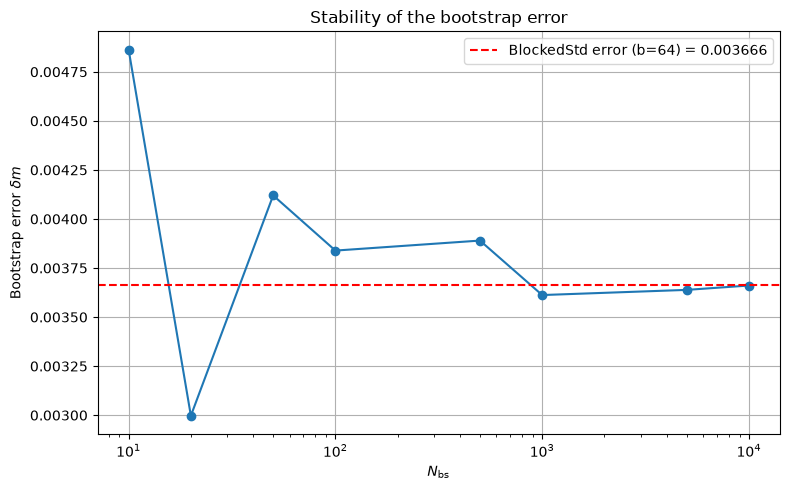


Comparison of error estimates:
Naive standard error: 0.003666
Bootstrap error:      0.003661


In [33]:
# Bootstrap function
def bootstrap(m_samples, N_bs, rng):
    N_samples = len(m_samples)

    bootstrap_means = np.empty(N_bs)

    for i in range(N_bs):

        # Draw samples with replacement
        bootstrap_samples = rng.choice(
            m_samples,
            size=N_samples,
            replace=True
        )

        # Calculate mean of bootstrap list
        bootstrap_means[i] = np.mean(bootstrap_samples)

    # Calculate standard deviation of bootstrap means
    bootstrap_error = np.std(bootstrap_means, ddof=1)

    return bootstrap_error


# Number of bootstrap lists
N_bs_values = [10, 20, 50, 100, 500, 1000, 5000, 10000]

# Choose block size
b = 64

# Use previously generated blocked data
blocked_samples = blocked_data[b]

# Separate random number generator for bootstrap
rng_bootstrap = np.random.default_rng(seed=12345)

# Calculate bootstrap errors
bootstrap_errors = []

for N_bs in N_bs_values:

    error = bootstrap(
        blocked_samples,
        N_bs,
        rng_bootstrap
    )

    bootstrap_errors.append(error)

    print(
        f"N_bs = {N_bs:5d}: "
        f"Bootstrap error = {error:.6f}"
    )


# Plot stability of bootstrap error


fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(N_bs_values, bootstrap_errors, "o-")
# reference from task 3
ax.axhline(
    y=standard_errors[b],
    color="red",
    linestyle="--",
    label=rf"BlockedStd error (b={b}) = {standard_errors[b]:.6f}"
)
ax.set_xlabel(r"$N_{\mathrm{bs}}$")
ax.set_ylabel(r"Bootstrap error $\delta m$")
ax.set_title("Stability of the bootstrap error")

ax.set_xscale("log")
ax.grid(True)

plt.legend()
plt.tight_layout()
plt.show()


# Compare bootstrap error with naive standard error


naive_error = standard_errors[b]
bootstrap_error = bootstrap_errors[-1]

print("\nComparison of error estimates:")
print(f"Naive standard error: {naive_error:.6f}")
print(f"Bootstrap error:      {bootstrap_error:.6f}")

Block size b =  1: Bootstrap error = 0.000990, Naive standard error = 0.000994
Block size b =  2: Bootstrap error = 0.001335, Naive standard error = 0.001360
Block size b =  4: Bootstrap error = 0.001830, Naive standard error = 0.001838
Block size b =  8: Bootstrap error = 0.002399, Naive standard error = 0.002415
Block size b = 16: Bootstrap error = 0.002987, Naive standard error = 0.002986
Block size b = 32: Bootstrap error = 0.003416, Naive standard error = 0.003468
Block size b = 64: Bootstrap error = 0.003696, Naive standard error = 0.003666


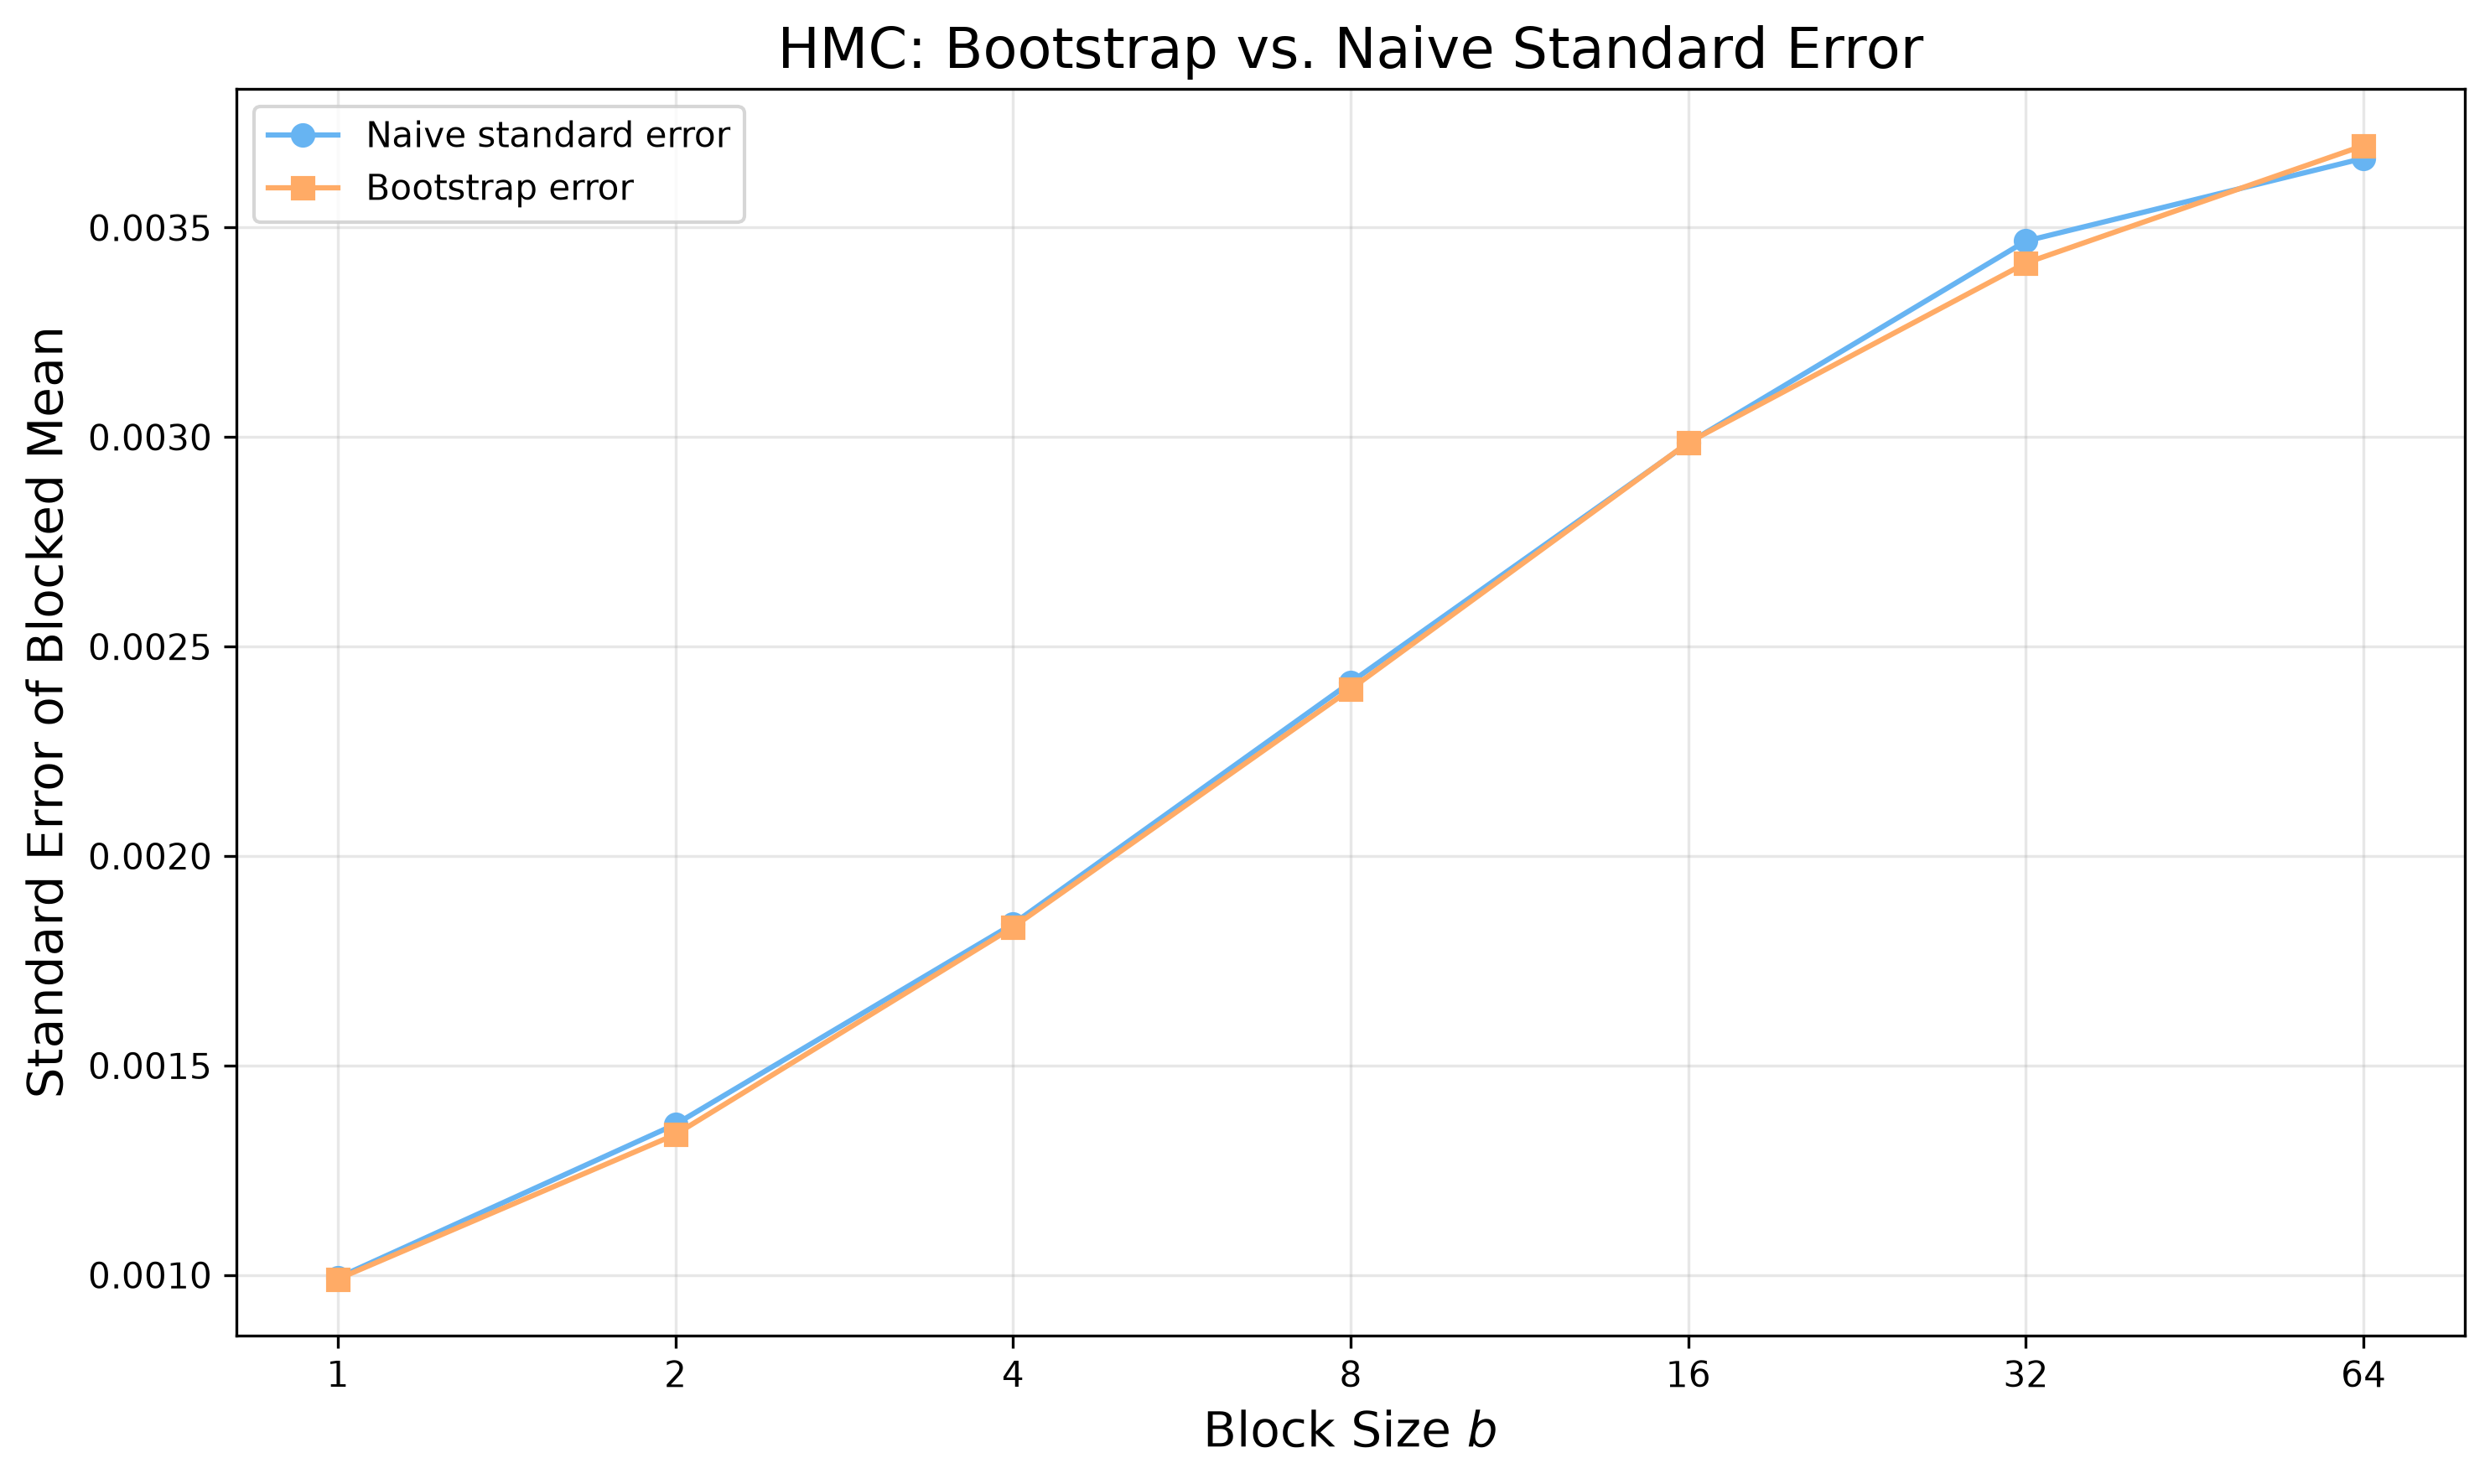

In [29]:
# =============================================================
# Task 4: Bootstrap error vs. naive std err

N_bs = 5000
rng = np.random.default_rng(seed=123)

bootstrap_errors_by_block = []

for b in block_sizes:

    blocked_samples = blocked_data[b]

    error = bootstrap(
        blocked_samples,
        N_bs,
        rng
    )

    bootstrap_errors_by_block.append(error)

    print(
        f"Block size b = {b:2d}: "
        f"Bootstrap error = {error:.6f}, "
        f"Naive standard error = {standard_errors[b]:.6f}"
    )

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)
ax.plot(
    block_sizes,
    standard_errors_list,
    marker="o",
    linewidth=1.5,
    color=colors[0],
    label="Naive standard error"
)
ax.plot(
    block_sizes,
    bootstrap_errors_by_block,
    marker="s",
    linewidth=1.5,
    color=colors[1],
    label="Bootstrap error"
)
ax.set_xscale("log", base=2)
ax.set_xticks(block_sizes)
ax.set_xticklabels(block_sizes)
ax.set_xlabel(r"Block Size $b$", fontsize=14)
ax.set_ylabel(r"Standard Error of Blocked Mean", fontsize=14)
ax.set_title("HMC: Bootstrap vs. Naive Standard Error", fontsize=16)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
# plt.savefig("figs/hmc_bootstrap_vs_naive_error.pdf", dpi=300)
# plt.savefig("figs/hmc_bootstrap_vs_naive_error.png", dpi=300)
plt.show()